In [1]:
adjacent_list = [
    [2,5],
    [1,3,4,5],
    [2,4],
    [2,3,5],
    [1,2,4]
]

In [2]:
print(adjacent_list)

[[2, 5], [1, 3, 4, 5], [2, 4], [2, 3, 5], [1, 2, 4]]


In [3]:
# Adjacent list conversion

def adjacentListToAdjacentMatrix(adjacent_list):
    matrix = []
    for i in range(len(adjacent_list)):
        row = [0] * len(adjacent_list)
        for j in adjacent_list[i]:
            row[j - 1] = 1
        matrix.append(row)
    return matrix

def adjacentListToIncidentsMatrix(adjacent_list):
    matrix = []
    for i in range(len(adjacent_list)):
        for j in adjacent_list[i]:
            if j - 1 >= i:
                col = [0] * len(adjacent_list)
                col[i] = 1
                col[j-1] = 1
                matrix.append(col)
    return matrix

# Adjacent matrix conversion

def adjacentMatrixToIncidentsMatrix(adjacent_matrix):
    matrix = []
    for i in range(len(adjacent_matrix)):
        for j in range(i + 1, len(adjacent_matrix)):
            if adjacent_matrix[i][j] == 1:
                col = [0] * len(adjacent_matrix)
                col[i] = 1
                col[j] = 1
                matrix.append(col)
    return matrix

def adjacentMatrixToAdjacentList(adjacent_matrix):
    adj_list = []
    for i in range(len(adjacent_matrix)):
        row = []
        for j in range(len(adjacent_matrix)):
            if adjacent_matrix[i][j] == 1:
                row.append(j + 1)
        adj_list.append(row)
    return adj_list

# Incident matrix conversion

def incidentsMatrixToAdjacentList(incidents_matrix):
    matrix = [] * len(incidents_matrix[0])
    for _ in range(len(incidents_matrix[0])):
        matrix.append([] * len(incidents_matrix[0]))
    for i in incidents_matrix:
        first, second = -1,-1
        for j in range(len(incidents_matrix[0])):
            if i[j] == 1:
                if first == -1:
                    first = j
                else:
                    second = j
                    break
        matrix[first].append(second + 1)
        matrix[second].append(first + 1)
            

    return matrix

def incidentsMatrixToAdjacentMatrix(incidents_matrix):
    matrix = [] * len(incidents_matrix[0])
    for _ in range(len(incidents_matrix[0])):
        matrix.append([0] * len(incidents_matrix[0]))
    for i in incidents_matrix:
        first, second = -1,-1
        for j in range(len(incidents_matrix[0])):
            if i[j] == 1:
                if first == -1:
                    first = j
                else:
                    second = j
                    break
        matrix[first][second] = 1
        matrix[second][first] = 1
            

    return matrix

In [4]:
print(adjacentListToAdjacentMatrix(adjacent_list))
print(incidentsMatrixToAdjacentMatrix(adjacentListToIncidentsMatrix(adjacent_list)))

print(adjacentMatrixToAdjacentList(adjacentListToAdjacentMatrix(adjacent_list)))
print(incidentsMatrixToAdjacentList(adjacentListToIncidentsMatrix(adjacent_list)))

print(adjacentListToIncidentsMatrix(adjacent_list))
print(adjacentMatrixToIncidentsMatrix(adjacentListToAdjacentMatrix(adjacent_list)))

[[0, 1, 0, 0, 1], [1, 0, 1, 1, 1], [0, 1, 0, 1, 0], [0, 1, 1, 0, 1], [1, 1, 0, 1, 0]]
[[0, 1, 0, 0, 1], [1, 0, 1, 1, 1], [0, 1, 0, 1, 0], [0, 1, 1, 0, 1], [1, 1, 0, 1, 0]]
[[2, 5], [1, 3, 4, 5], [2, 4], [2, 3, 5], [1, 2, 4]]
[[2, 5], [1, 3, 4, 5], [2, 4], [2, 3, 5], [1, 2, 4]]
[[1, 1, 0, 0, 0], [1, 0, 0, 0, 1], [0, 1, 1, 0, 0], [0, 1, 0, 1, 0], [0, 1, 0, 0, 1], [0, 0, 1, 1, 0], [0, 0, 0, 1, 1]]
[[1, 1, 0, 0, 0], [1, 0, 0, 0, 1], [0, 1, 1, 0, 0], [0, 1, 0, 1, 0], [0, 1, 0, 0, 1], [0, 0, 1, 1, 0], [0, 0, 0, 1, 1]]


In [ ]:
#Displaying
import networkx as nx
import matplotlib.pyplot as plt

def graphDisplay(adjecent_list, filename="graphs_output.jpg"):
    graph = nx.Graph()
    for i in range(len(adjecent_list)):
        graph.add_node(i + 1)
    for index, row in enumerate(adjecent_list):
        for i in row:
            graph.add_edge(i, index + 1)

    #For yupiter implementation to see output
    nx.draw_circular(graph, with_labels=True, node_color="skyblue",node_size=700,edge_color="gray",
        font_weight="bold")

    #For CLI in main program implementaton to see output
    # plt.figure()
    # nx.draw_circular(
    #     graph,
    #     with_labels=True,
    #     node_color="skyblue",
    #     node_size=700,
    #     edge_color="gray",
    #     font_weight="bold",
    # )

    # plt.savefig(filename, bbox_inches="tight", dpi=300)
    # plt.close()

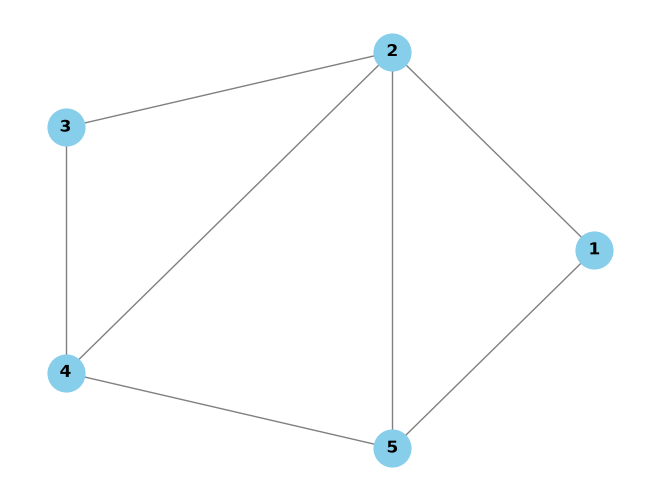

In [15]:
graphDisplay(adjacent_list)

In [7]:
#Graph generation
import random

def generateGraph(node_num = None, edge_num=None, random_chance_per_edge=None):
    if node_num == None:
        raise ValueError("Graph without node can't be created")
    if (edge_num == None and random_chance_per_edge == None) or (edge_num != None and random_chance_per_edge != None):
        raise ValueError("Chose one option edge_num (default) or random_chance_per_edge")

    outputAdjacentList = []
    if random_chance_per_edge != None:
        if (random_chance_per_edge < 0 or random_chance_per_edge > 1):
            raise("Bad random chance number")
        for _ in range(node_num):
            outputAdjacentList.append([])
        for i in range(node_num):
            for j in range(i + 1, node_num):
                if random_chance_per_edge >= random.random():
                    outputAdjacentList[i].append(j + 1)
                    outputAdjacentList[j].append(i + 1)
    elif edge_num != None:
        if edge_num < 0 or edge_num > (node_num* (node_num - 1)) // 2:
            raise ValueError("Bad edge number")
        matrix = [] * node_num
        for _ in range(node_num):
            matrix.append([0] * node_num)
        edges_generated = 0
        while edges_generated < edge_num:
            x, y = random.randint(0, node_num - 1), random.randint(0, node_num - 1)
            if x == y:
                continue
            if matrix[x][y] == 0:
                matrix[x][y] = 1
                matrix[y][x] = 1
                edges_generated = edges_generated + 1

        outputAdjacentList = adjacentMatrixToAdjacentList(matrix)

    return outputAdjacentList


[[2, 3, 4, 5], [1, 7], [1, 5, 6], [1, 6, 7], [1, 3, 7], [3, 4], [2, 4, 5]]


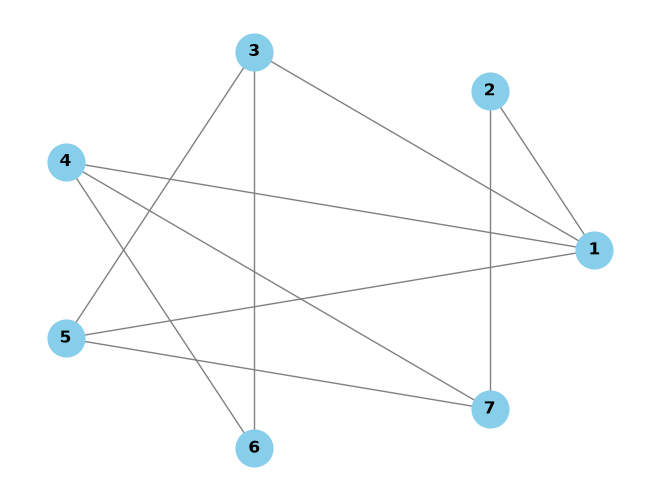

In [8]:
generatedG_n_l = generateGraph(node_num=7, edge_num=10)
print(generatedG_n_l)
graphDisplay(generatedG_n_l)

[[], [7], [], [], [], [], [2]]


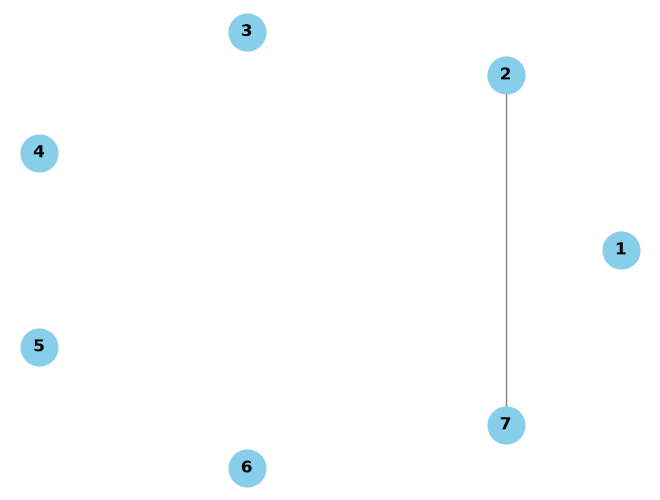

In [9]:
generatedG_n_l2 = generateGraph(node_num=7, edge_num=1)
print(generatedG_n_l2)
graphDisplay(generatedG_n_l2)

[[], [], [], [], [], [], []]


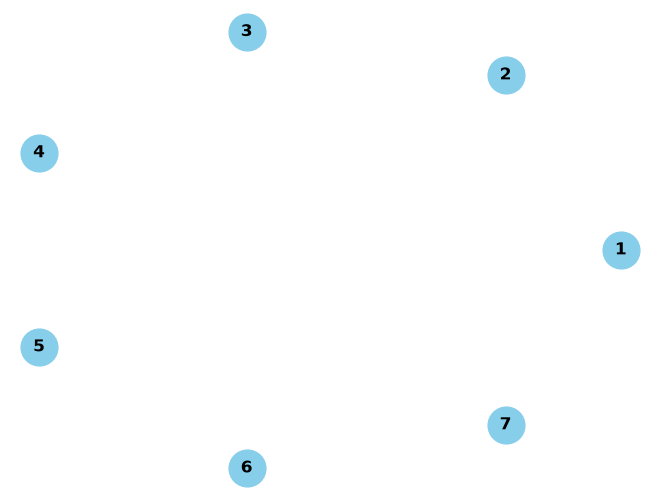

In [10]:
generatedG_n_p = generateGraph(node_num=7, random_chance_per_edge=0)
print(generatedG_n_p)
graphDisplay(generatedG_n_p)

[[], [], [], [], [], [], []]


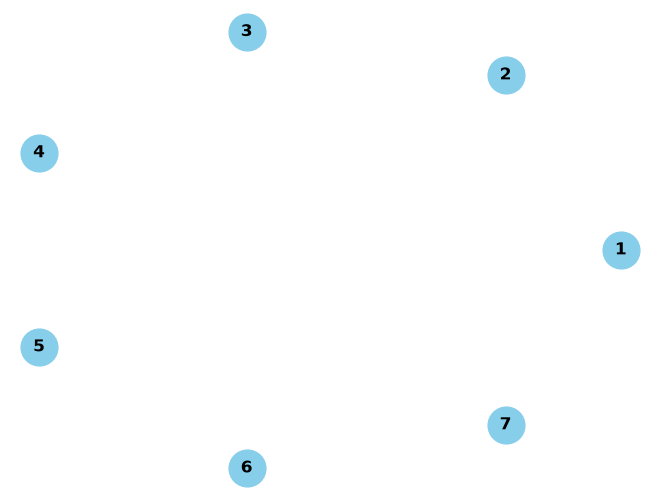

In [11]:
generatedG_n_p2 = generateGraph(node_num=7, random_chance_per_edge=0)
print(generatedG_n_p2)
graphDisplay(generatedG_n_p2)